### <font color = "gold"> Import les librairies requises

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px


In [2]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [3]:
# Importer les données
df = pd.read_csv('/content/sample_data/heart_failure_clinical_records_dataset.csv')

Cet ensemble de données contient les dossiers médicaux de 299 patients atteints d'insuffisance cardiaque, recueillis au cours de leur période de suivi, où chaque profil de patient comporte 13 caractéristiques cliniques.
| Variable | Type | Description |
|----------|------|-------------|
| `age` | Numérique | âge du patient. |
| `anaemia` | Numérique | diminution des globules rouges ou de l'hémoglobine. |
| `creatinine_phosphokinase` | Numérique | taux de l'enzyme CPK dans le sang. |
| `diabetest` | Numérique |si le patient est diabétique. |
| `ejection_fraction` | Numérique | pourcentage de sang quittant le cœur à chaque contraction. |
| `high_blood_pressuree` | si le patient souffre d'hypertension. |
| `platelets` | Numérique | plaquettes dans le sang. |
| `serum_creatinine` | Numérique | taux de créatinine sérique dans le sangt. |
| `serum_sodium` | Numérique | taux de sodium sérique dans le sang. |
| `sex` | Numérique | femme ou homme. |
| `smoking` | Numérique | si le patient fume ou non	. |
| `time` | Numérique |période de suivi. |
| `death_event` | Numérique | si le patient décède pendant la période de suiv |

In [4]:
# Afficher les données
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


####  <font color = "gold" > Explorer les données

In [5]:
# Dimension des données
df.shape

(299, 13)

In [6]:
#infos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [7]:
# Décrire les données
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


In [8]:
#chercher les doublon
df.duplicated().sum()

np.int64(0)

In [9]:
# renommer les index
df.index = ['Patient' + str(i+1) for i in range(len(df))]
df.index.name = "patient_id"

In [10]:
# Données en format matriciel
x = df.values
x[:5]

array([[7.5000000e+01, 0.0000000e+00, 5.8200000e+02, 0.0000000e+00,
        2.0000000e+01, 1.0000000e+00, 2.6500000e+05, 1.9000000e+00,
        1.3000000e+02, 1.0000000e+00, 0.0000000e+00, 4.0000000e+00,
        1.0000000e+00],
       [5.5000000e+01, 0.0000000e+00, 7.8610000e+03, 0.0000000e+00,
        3.8000000e+01, 0.0000000e+00, 2.6335803e+05, 1.1000000e+00,
        1.3600000e+02, 1.0000000e+00, 0.0000000e+00, 6.0000000e+00,
        1.0000000e+00],
       [6.5000000e+01, 0.0000000e+00, 1.4600000e+02, 0.0000000e+00,
        2.0000000e+01, 0.0000000e+00, 1.6200000e+05, 1.3000000e+00,
        1.2900000e+02, 1.0000000e+00, 1.0000000e+00, 7.0000000e+00,
        1.0000000e+00],
       [5.0000000e+01, 1.0000000e+00, 1.1100000e+02, 0.0000000e+00,
        2.0000000e+01, 0.0000000e+00, 2.1000000e+05, 1.9000000e+00,
        1.3700000e+02, 1.0000000e+00, 0.0000000e+00, 7.0000000e+00,
        1.0000000e+00],
       [6.5000000e+01, 1.0000000e+00, 1.6000000e+02, 1.0000000e+00,
        2.0000000e+0

In [11]:
# Importer Normalizer (même méthode que normalize(), mais réutilisable dans l'application)
from sklearn.preprocessing import Normalizer
# Instantier le normaliseur
scaler = Normalizer()
# Normaliser les données
x = scaler.fit_transform(df)
x[:5]

array([[2.83018139e-04, 0.00000000e+00, 2.19622076e-03, 0.00000000e+00,
        7.54715038e-05, 3.77357519e-06, 9.99997425e-01, 7.16979286e-06,
        4.90564774e-04, 3.77357519e-06, 0.00000000e+00, 1.50943008e-05,
        3.77357519e-06],
       [2.08748165e-04, 0.00000000e+00, 2.98358060e-02, 0.00000000e+00,
        1.44226005e-04, 0.00000000e+00, 9.99554647e-01, 4.17496331e-06,
        5.16177282e-04, 3.79542119e-06, 0.00000000e+00, 2.27725271e-05,
        3.79542119e-06],
       [4.01234242e-04, 0.00000000e+00, 9.01233836e-04, 0.00000000e+00,
        1.23456690e-04, 0.00000000e+00, 9.99999188e-01, 8.02468484e-06,
        7.96295649e-04, 6.17283449e-06, 6.17283449e-06, 4.32098414e-05,
        6.17283449e-06],
       [2.38095146e-04, 4.76190292e-06, 5.28571225e-04, 0.00000000e+00,
        9.52380585e-05, 0.00000000e+00, 9.99999614e-01, 9.04761556e-06,
        6.52380701e-04, 4.76190292e-06, 0.00000000e+00, 3.33333205e-05,
        4.76190292e-06],
       [1.98776718e-04, 3.05810335e-

In [12]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [13]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(99.67)

### <font color='gold'> Kmeans

In [14]:
# Importer KMeans
from sklearn.cluster import KMeans

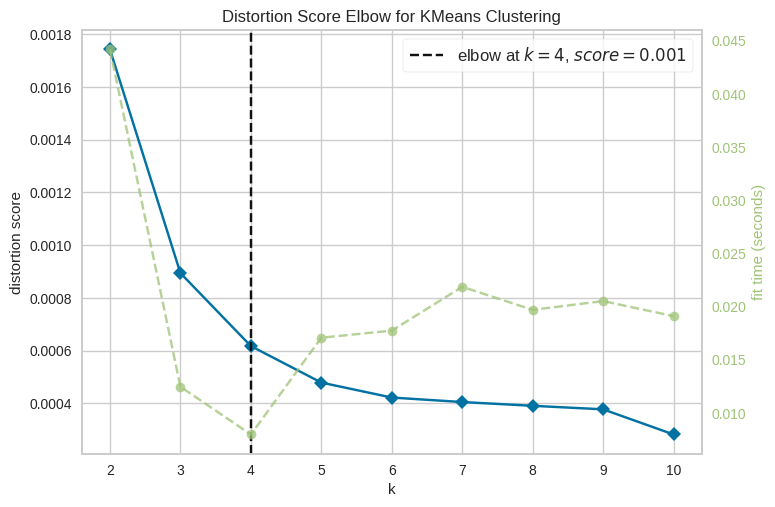

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [15]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

In [16]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 4, init = 'random', max_iter = 500)
# Entrainer le modèle
kmeans_model.fit(x)

KMeans(init='random', max_iter=500, n_clusters=4)

#### <font color='teal'> Prédiction

In [17]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[: 100]

array([0, 1, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 0, 2, 3, 2, 2,
       2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 0, 2, 0, 3, 2, 0, 2, 0, 2,
       0, 0, 0, 2, 0, 2, 0, 2, 3, 2, 2, 2, 2, 0, 0, 2, 1, 2, 2, 2, 0, 2,
       2, 2, 2, 2, 2, 0, 1, 2, 0, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 0, 2, 2, 2], dtype=int32)

In [18]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

,count
2,183
0,84
3,22
1,10


In [19]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [20]:
# visualiser le diagramme des nombres d'observations
bar_plot(val)

In [21]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

In [22]:
# Visualiser les classes
scatter_plot(New_df,kmeans_partition)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [23]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(x,kmeans_partition)
print(f"La silhouette score : {sil_kmeans} ")

La silhouette score : 0.5850686265231654 


### <font color='gold'> CAH

In [24]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

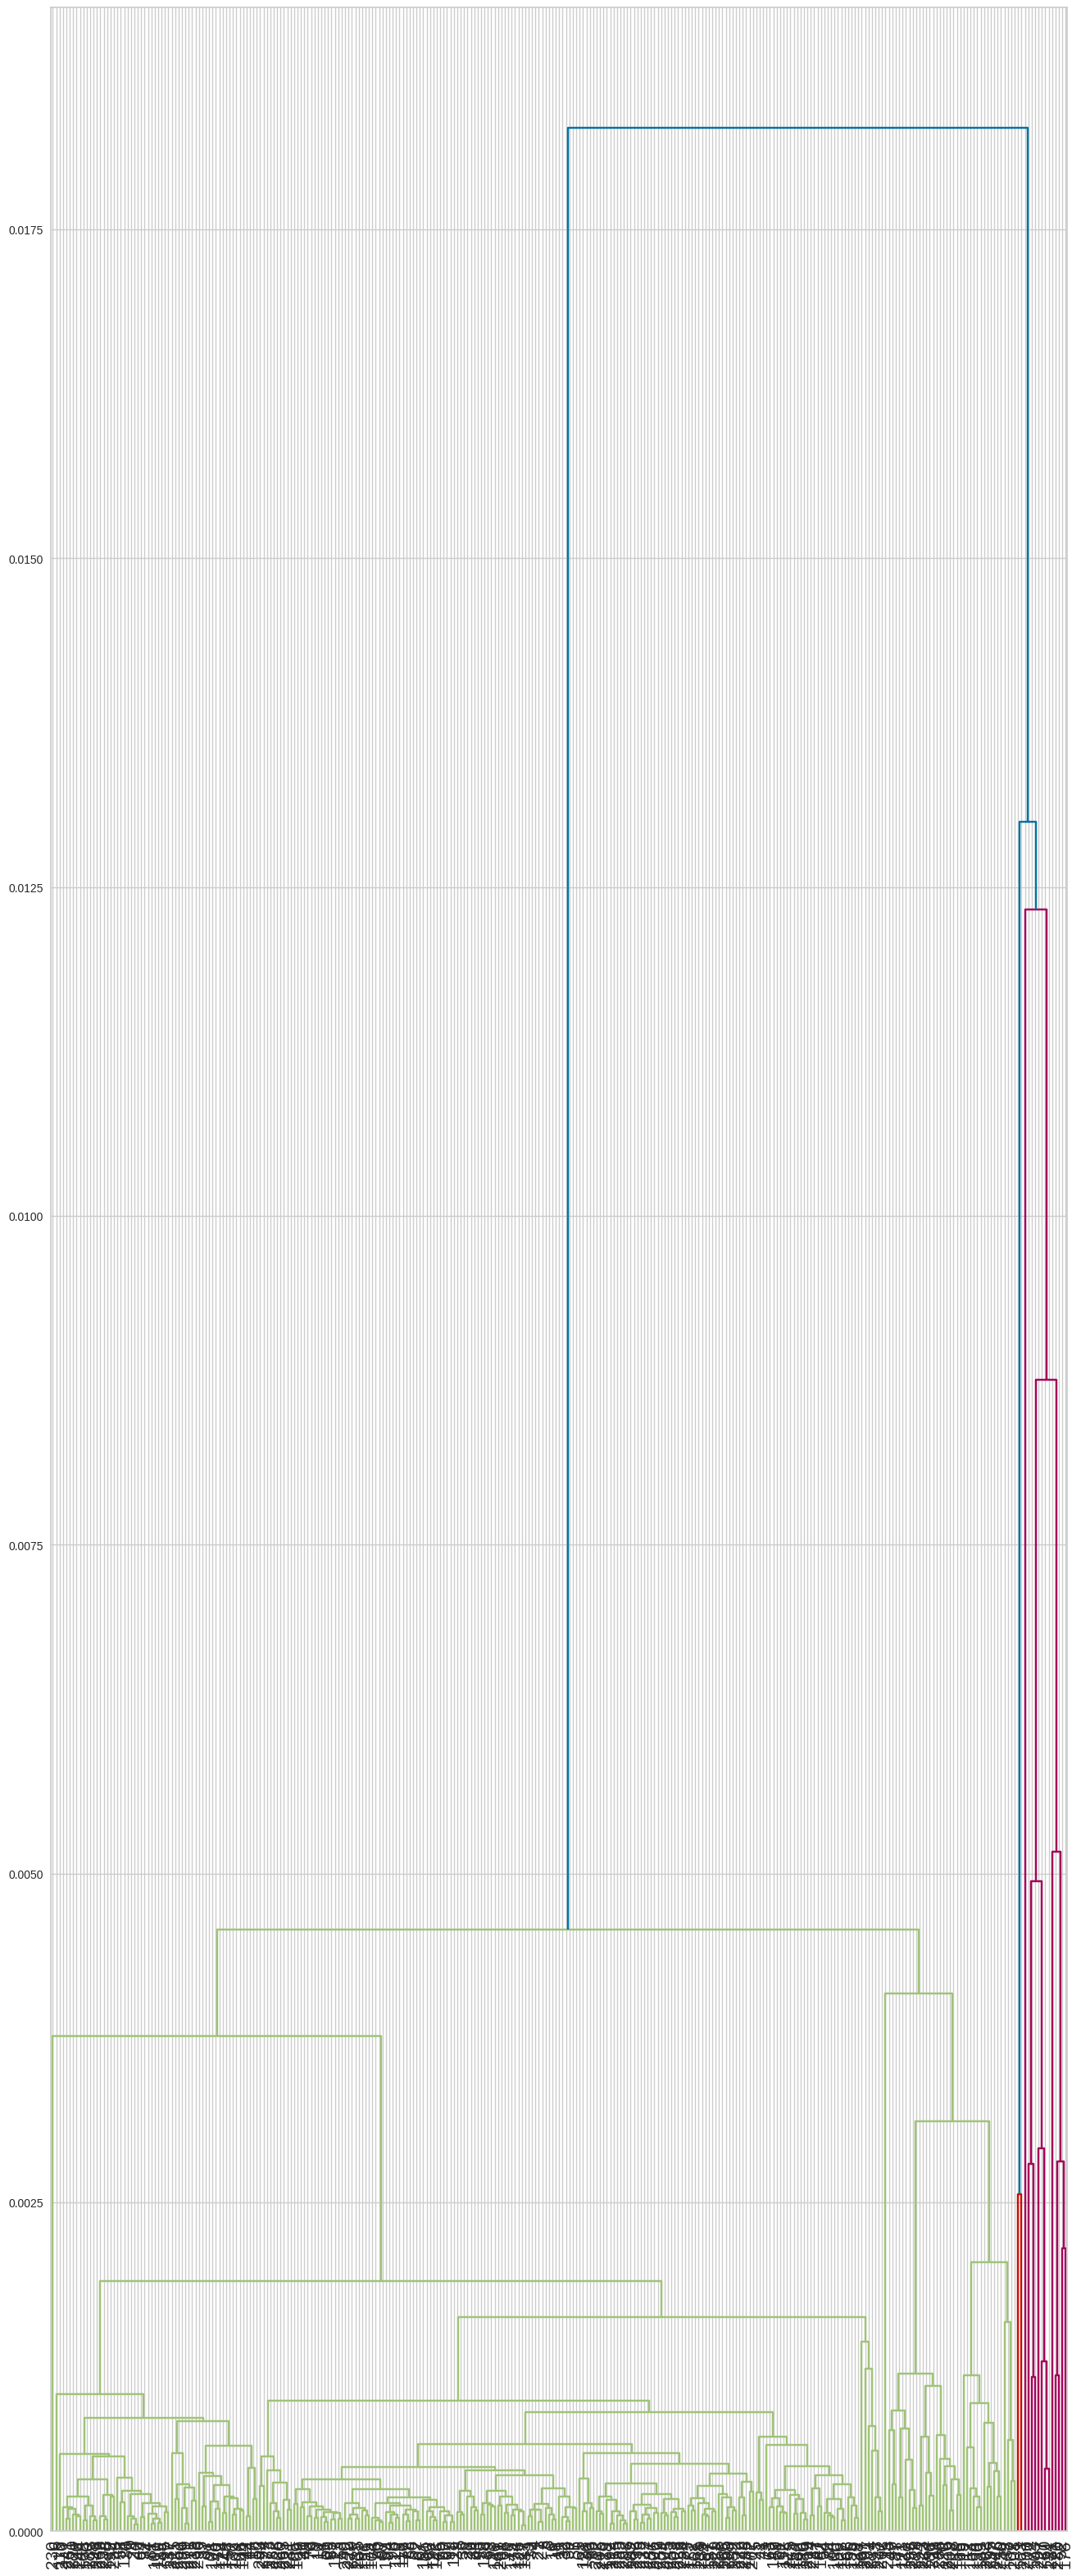

In [25]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(16, 40))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [26]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =2, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

AgglomerativeClustering(linkage='average')

In [27]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [28]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

,count
1,284
0,15


In [29]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [30]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [31]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"La silhouette score :{sil_cah}")

La silhouette score :0.8603343921409614


In [32]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [33]:
# les indidivus
cluster_names = []
for i in range(2):
  cluster_names.append(list(df.index[cah_partition == i]))

In [34]:
# Les individus de la classe 0
print(cluster_names[0])

['Patient2', 'Patient53', 'Patient61', 'Patient73', 'Patient104', 'Patient135', 'Patient164', 'Patient172', 'Patient177', 'Patient201', 'Patient228', 'Patient278', 'Patient281', 'Patient282', 'Patient298']


### <font color = "gold"> Interpréter les classes

Avant de déployer le modèle, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [35]:
# Profil moyen de chaque classe
profil = df.groupby(cah_partition).mean().round(3)
profil

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,60.800,0.200,3580.667,0.333,38.400,0.133,186187.737,1.519,138.467,0.867,0.467,147.267,0.333
1,60.836,0.444,423.451,0.423,38.067,0.363,267433.925,1.387,136.528,0.637,0.313,129.363,0.320


In [36]:
# Noms des classes
noms_classes = {
    0: "Patient avec CPK très élevé (profil atypique)",
    1: "Patient au profil standard",
}

### <font color = "gold"> Préparer le meilleur modèle (CAH) pour le déploiement



In [37]:
from sklearn.neighbors import NearestCentroid
# Instantier le modèle des centroïdes de la CAH
model = NearestCentroid()
# Entrainer sur les classes trouvées par la CAH
model.fit(x, cah_partition)
# Vérifier que le modèle retrouve bien la partition de la CAH
print("Concordance avec la CAH :", (model.predict(x) == cah_partition).mean())

Concordance avec la CAH : 1.0


In [38]:
# Test rapide sur le première patient
patient = scaler.transform(df.iloc[[0]])
print("Classe prédite         :", noms_classes[model.predict(patient)[0]])
print("Classe réelle de la CAH:", noms_classes[cah_partition[0]])

Classe prédite         : Patient au profil standard
Classe réelle de la CAH: Patient au profil standard


In [39]:
# Test sur un patient de la classe 0 (Patient4 est dans votre liste)
patient4 = scaler.transform(df.loc[["Patient4"]].values)
print("Classe prédite         :", noms_classes[model.predict(patient4)[0]])
print("Classe réelle de la CAH:", noms_classes[cah_partition[1]])

Classe prédite         : Patient au profil standard
Classe réelle de la CAH: Patient avec CPK très élevé (profil atypique)


### <font color = "gold"> Sauvegarde des modèles (joblib)

On enregistre le normaliseur, l'ACP et le modèle dans le même dossier que les données.
L'application Streamlit `app_wheat.py` les chargera.

In [40]:
import os
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)

In [41]:
import joblib
import sklearn
# Dossier de sauvegarde
# Enregistrer le normaliseur, l'ACP et le modèle
joblib.dump(scaler, '/content/model/scaler_heart.joblib')
joblib.dump(pca_model, '/content/model/pca_heart.joblib')
joblib.dump(model, '/content/model/model_heart.joblib')
# Version de scikit-learn à installer aussi pour Streamlit
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1
